In [112]:
import numpy as np
import random
import matplotlib.pyplot as plt

In [105]:
def generate_spirals ( n_points =500 , noise =0.2) :
    n = np . sqrt ( np . random . rand ( n_points , 1) ) * 780 * (2 * np . pi ) / 360
    d1x = - np . cos ( n ) * n + np . random . randn ( n_points , 1) * noise
    d1y = np . sin ( n ) * n + np . random . randn ( n_points , 1) * noise
    d2x = np . cos ( n ) * n + np . random . randn ( n_points , 1) * noise
    d2y = - np . sin ( n ) * n + np . random . randn ( n_points , 1) * noise
    X = np . vstack (( np . hstack (( d1x , d1y ) ) , np . hstack (( d2x , d2y ) ) ) )
    y = np . vstack (( np . zeros (( n_points , 1) ) , np . ones (( n_points , 1) ) ) )
    return X / np . max ( np . abs ( X ) ) , y

In [113]:
class CategoricalCrossEntropy(object):
    @staticmethod
    def fn(a, y):
        a = np.clip(a, 1e-12, 1 - 1e-12)
        return np.sum(-y*np.log(a) - (1-y)*np.log(1-a))

    @staticmethod
    def delta(a, y):
        return (a - y)

def sigmoid(z):
    return 1.0/(1.0+np.exp(-z))
def sigmoid_prime(z):
    return sigmoid(z)*(1-sigmoid(z))

def relu(z):
    return np.maximum(0, z)
def relu_prime(z):
    return (z>0).astype(float)
ACTIVATIONS = {'sigmoid': (sigmoid, sigmoid_prime), 'relu': (relu, relu_prime)}

def set_seed(s=42):
    np.random.seed(s)
    random.seed(s)

In [107]:
class Network(object):
    def __init__(self, sizes, cost=CategoricalCrossEntropy, activation='relu', init='he'):
        self.n_layers = len(sizes)
        self.sizes = sizes
        self.cost = cost
        self.act, self.act_prime = ACTIVATIONS[activation]
        self.init_weights(init)

    def init_weights(self, kind):
        scale = {'normal': lambda n: 1.0,
                 'xavier': lambda n: 1.0 / np.sqrt(n),
                 'he':     lambda n: np.sqrt(2.0 / n)}[kind]
        self.biases = [np.random.randn(y, 1) for y in self.sizes[1:]]
        self.weights = [np.random.randn(y, x) * scale(x) for x, y in zip(self.sizes[:-1], self.sizes[1:])]
        
    def feedforward(self, a):
        for b,w in zip(self.biases[:-1], self.weights[:-1]):
            a = self.act(np.dot(w, a) + b)
        return sigmoid(np.dot(self.weights[-1], a) + self.biases[-1])

    def SGD(self, training_data, epochs, mini_batch_size, eta, lmbda=0.0,
        evaluation_data=None, verbose=True):
        training_data = list(training_data)
        n = len(training_data)
        n_data = len(evaluation_data) if evaluation_data else 0
    
        history = {'train_cost': [], 'train_acc': [],
                   'val_cost': [], 'val_acc': []}
    a
        for j in range(epochs):
            random.shuffle(training_data)
            mini_batches = [training_data[k:k+mini_batch_size]
                            for k in range(0, n, mini_batch_size)]
            cur_eta = eta * (0.5 ** (j // 100))
            for mini_batch in mini_batches:
                self.update_mini_batch(mini_batch, cur_eta, lmbda, n)
    
            # метрики в конце эпохи (в процентах для точности)
            history['train_cost'].append(self.total_cost(training_data, lmbda))
            train_correct = sum(int(np.argmax(self.feedforward(x)) == np.argmax(y))
                                for x, y in training_data)
            history['train_acc'].append(100.0 * train_correct / n)
    
            if evaluation_data:
                history['val_cost'].append(
                    self.total_cost(evaluation_data, lmbda, convert=True, n_reg=n))
                history['val_acc'].append(
                    100.0 * self.evaluate(evaluation_data) / n_data)
    
            if verbose and (j % 10 == 0 or j == epochs - 1):
                msg = f"Epoch {j}: train acc {history['train_acc'][-1]:.1f}%"
                if evaluation_data:
                    msg += f", val acc {history['val_acc'][-1]:.1f}%"
                print(msg)
    
        return history

    def update_mini_batch(self, mini_batch, eta, lmbda, n):
        nabla_b = [np.zeros(b.shape) for b in self.biases]
        nabla_w = [np.zeros(w.shape) for w in self.weights]
        for x,y in mini_batch:
            delta_nabla_b, delta_nabla_w = self.backprop(x, y)
            nabla_b = [nb+dnb for nb, dnb in zip(nabla_b, delta_nabla_b)]
            nabla_w = [nw+dnw for nw, dnw in zip(nabla_w, delta_nabla_w)]
        self.weights = [(1-(eta*lmbda)/n)*w - (eta/len(mini_batch))*nw for w, nw in zip(self.weights, nabla_w)]
        self.biases = [b - (eta/len(mini_batch))*nb for b, nb in zip(self.biases, nabla_b)]

    def backprop(self, x, y):
        nabla_b = [np.zeros(b.shape) for b in self.biases]
        nabla_w = [np.zeros(w.shape) for w in self.weights]
        zs = []
        activations = [x]
        for i, (b, w) in enumerate(zip(self.biases, self.weights)):
            z = np.dot(w, activations[-1]) + b
            zs.append(z)
            f = sigmoid if i == len(self.weights) - 1 else self.act
            activations.append(f(z))
        delta = self.cost.delta(activations[-1], y)
        nabla_b[-1] = delta
        nabla_w[-1] = np.dot(delta, activations[-2].transpose())
        for l in range(2, self.n_layers):
            z = zs[-l]
            sp = self.act_prime(z)
            delta = np.dot(self.weights[-l+1].transpose(), delta) * sp
            nabla_b[-l] = delta
            nabla_w[-l] = np.dot(delta, activations[-l-1].transpose())
        return (nabla_b, nabla_w)

    def evaluate(self, evaluation_data):
        results = [(np.argmax(self.feedforward(x)), y) for (x,y) in evaluation_data]
        return sum(int(x==y) for (x,y) in results)

    def total_cost(self, data, lmbda=0.0, convert=False, n_reg=None):
        n_reg = n_reg or len(data)
        cost = 0.0
        for x, y in data:
            a = self.feedforward(x)
            if convert:
                y = vec(y)
            cost += self.cost.fn(a, y) / len(data)
        cost += 0.5 * (lmbda / n_reg) * sum(np.linalg.norm(w)**2 for w in self.weights)
        return cost

        

In [108]:
def vec(j):
    e = np.zeros((2,1)); e[j]=1.0
    return e


def plot_boundary(net, X, y):
    xx, yy = np.meshgrid(np.linspace(-1, 1, 300), np.linspace(-1, 1, 300))
    grid = np.c_[xx.ravel(), yy.ravel()].T          # (2, 90000)
    Z = np.argmax(net.feedforward(grid), axis=0).reshape(xx.shape)
    plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
    plt.scatter(X[:, 0], X[:, 1], c=y.ravel(), cmap='coolwarm', edgecolors='k', s=15)
    plt.title('Decision boundary')
    plt.show()

def plot_history(history):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(history['train_cost'], label='train')
    if history['val_cost']:
        axes[0].plot(history['val_cost'], label='validation')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Cost')
    axes[0].set_title('Cost')
    axes[0].grid(True)
    axes[0].legend()

    axes[1].plot(history['train_acc'], label='train')
    if history['val_acc']:
        axes[1].plot(history['val_acc'], label='validation')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Accuracy (%)')
    axes[1].set_title('Accuracy')
    axes[1].grid(True)
    axes[1].legend()

    plt.tight_layout()
    plt.show()

Epoch 0: train acc 59.7%, val acc 55.0%
Epoch 10: train acc 65.5%, val acc 59.5%
Epoch 20: train acc 69.8%, val acc 67.5%
Epoch 30: train acc 72.8%, val acc 69.0%
Epoch 40: train acc 76.3%, val acc 76.5%
Epoch 50: train acc 77.7%, val acc 80.5%
Epoch 60: train acc 83.8%, val acc 83.5%
Epoch 70: train acc 84.0%, val acc 84.5%
Epoch 80: train acc 87.0%, val acc 86.0%
Epoch 90: train acc 83.3%, val acc 79.5%
Epoch 100: train acc 89.3%, val acc 85.5%
Epoch 110: train acc 95.0%, val acc 91.0%
Epoch 120: train acc 93.7%, val acc 87.5%
Epoch 130: train acc 96.5%, val acc 93.0%
Epoch 140: train acc 96.0%, val acc 92.0%
Epoch 150: train acc 97.5%, val acc 93.5%
Epoch 160: train acc 97.8%, val acc 93.5%
Epoch 170: train acc 97.8%, val acc 94.5%
Epoch 180: train acc 99.0%, val acc 96.0%
Epoch 190: train acc 99.0%, val acc 95.0%
Epoch 200: train acc 99.2%, val acc 95.5%
Epoch 210: train acc 98.8%, val acc 95.0%
Epoch 220: train acc 98.8%, val acc 95.0%
Epoch 230: train acc 99.0%, val acc 95.0%
Epo

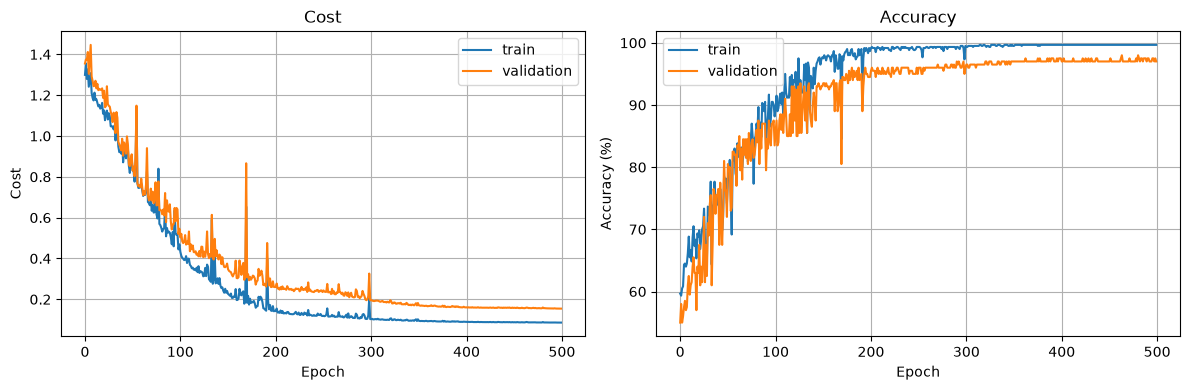

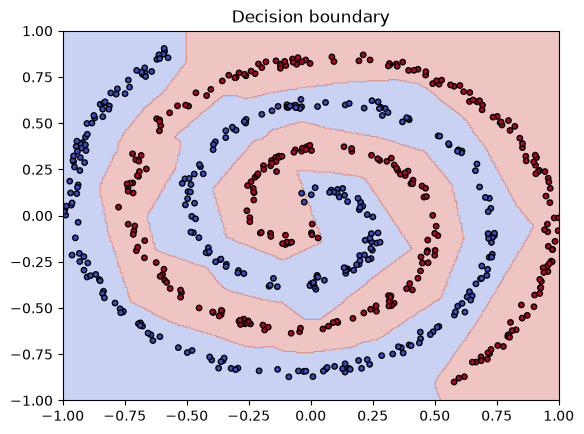

Epoch 0: train acc 61.0%, val acc 55.5%
Epoch 10: train acc 61.8%, val acc 55.0%
Epoch 20: train acc 65.3%, val acc 58.5%
Epoch 30: train acc 62.8%, val acc 56.5%
Epoch 40: train acc 62.3%, val acc 55.0%
Epoch 50: train acc 64.8%, val acc 58.5%
Epoch 60: train acc 65.0%, val acc 59.5%
Epoch 70: train acc 62.8%, val acc 58.5%
Epoch 80: train acc 65.2%, val acc 59.0%
Epoch 90: train acc 65.8%, val acc 61.0%
Epoch 100: train acc 65.2%, val acc 59.5%
Epoch 110: train acc 63.3%, val acc 57.5%
Epoch 120: train acc 64.5%, val acc 59.0%
Epoch 130: train acc 64.3%, val acc 58.5%
Epoch 140: train acc 63.7%, val acc 58.0%
Epoch 150: train acc 66.7%, val acc 61.0%
Epoch 160: train acc 64.3%, val acc 58.5%
Epoch 170: train acc 66.3%, val acc 61.5%
Epoch 180: train acc 64.7%, val acc 56.5%
Epoch 190: train acc 64.7%, val acc 58.0%
Epoch 200: train acc 64.5%, val acc 56.5%
Epoch 210: train acc 66.3%, val acc 60.5%
Epoch 220: train acc 66.2%, val acc 60.0%
Epoch 230: train acc 64.8%, val acc 56.5%
Epo

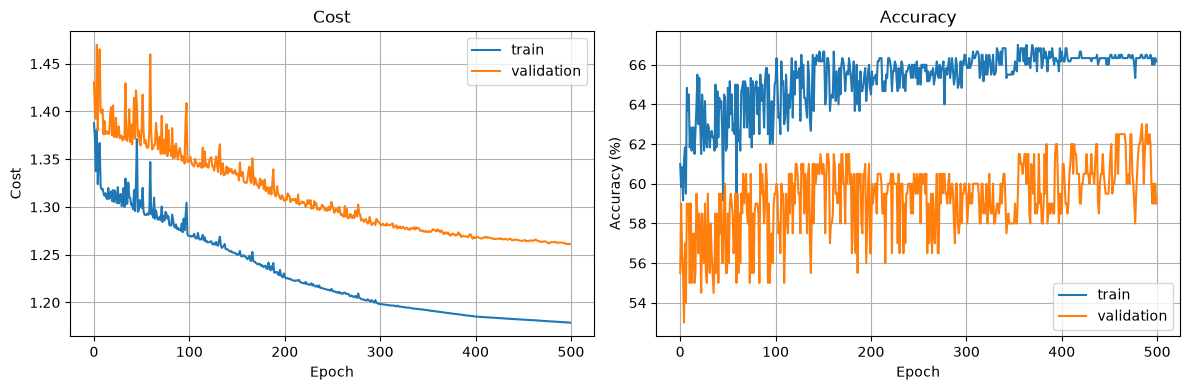

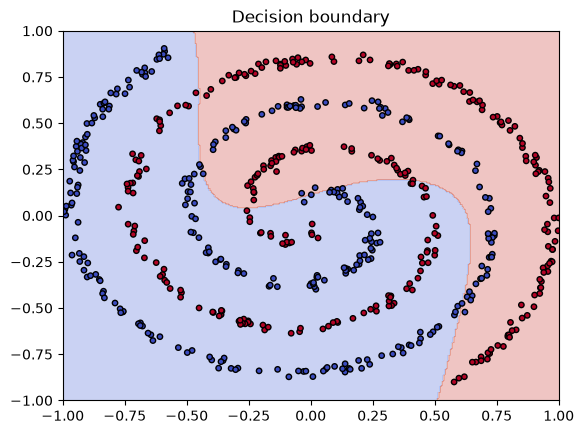

Epoch 0: train acc 56.7%, val acc 56.5%
Epoch 10: train acc 59.2%, val acc 55.0%
Epoch 20: train acc 60.0%, val acc 55.0%
Epoch 30: train acc 64.3%, val acc 59.0%
Epoch 40: train acc 66.2%, val acc 64.0%
Epoch 50: train acc 66.8%, val acc 63.0%
Epoch 60: train acc 71.3%, val acc 68.0%
Epoch 70: train acc 67.8%, val acc 68.0%
Epoch 80: train acc 66.7%, val acc 65.5%
Epoch 90: train acc 70.0%, val acc 68.0%
Epoch 100: train acc 75.2%, val acc 79.5%
Epoch 110: train acc 77.3%, val acc 80.5%
Epoch 120: train acc 79.2%, val acc 79.5%
Epoch 130: train acc 79.7%, val acc 82.5%
Epoch 140: train acc 80.5%, val acc 85.0%
Epoch 150: train acc 80.2%, val acc 80.0%
Epoch 160: train acc 82.3%, val acc 83.5%
Epoch 170: train acc 81.8%, val acc 82.0%
Epoch 180: train acc 83.8%, val acc 81.5%
Epoch 190: train acc 83.7%, val acc 85.0%
Epoch 200: train acc 84.2%, val acc 82.0%
Epoch 210: train acc 84.0%, val acc 81.5%
Epoch 220: train acc 84.3%, val acc 82.5%
Epoch 230: train acc 84.5%, val acc 82.5%
Epo

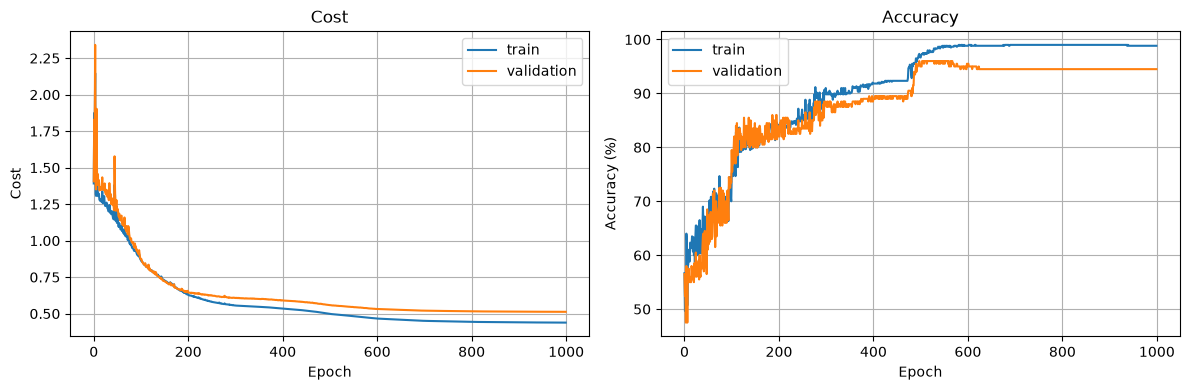

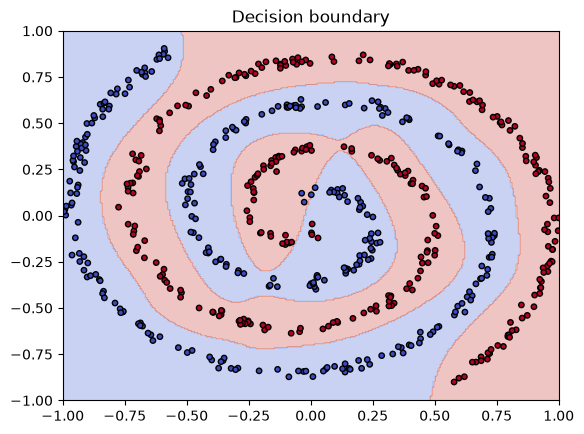

Epoch 0: train acc 50.3%, val acc 47.5%
Epoch 10: train acc 58.0%, val acc 54.5%
Epoch 20: train acc 63.2%, val acc 58.0%
Epoch 30: train acc 62.3%, val acc 53.0%
Epoch 40: train acc 62.3%, val acc 55.5%
Epoch 50: train acc 63.5%, val acc 57.5%
Epoch 60: train acc 63.2%, val acc 58.0%
Epoch 70: train acc 62.3%, val acc 57.5%
Epoch 80: train acc 62.7%, val acc 58.5%
Epoch 90: train acc 63.7%, val acc 57.5%
Epoch 100: train acc 62.8%, val acc 59.0%
Epoch 110: train acc 62.7%, val acc 57.0%
Epoch 120: train acc 62.3%, val acc 58.0%
Epoch 130: train acc 62.3%, val acc 58.0%
Epoch 140: train acc 62.3%, val acc 58.0%
Epoch 150: train acc 63.0%, val acc 59.0%
Epoch 160: train acc 62.8%, val acc 59.0%
Epoch 170: train acc 63.0%, val acc 59.0%
Epoch 180: train acc 62.8%, val acc 56.0%
Epoch 190: train acc 62.3%, val acc 57.0%
Epoch 200: train acc 62.3%, val acc 58.0%
Epoch 210: train acc 63.0%, val acc 58.5%
Epoch 220: train acc 63.2%, val acc 58.0%
Epoch 230: train acc 62.3%, val acc 58.0%
Epo

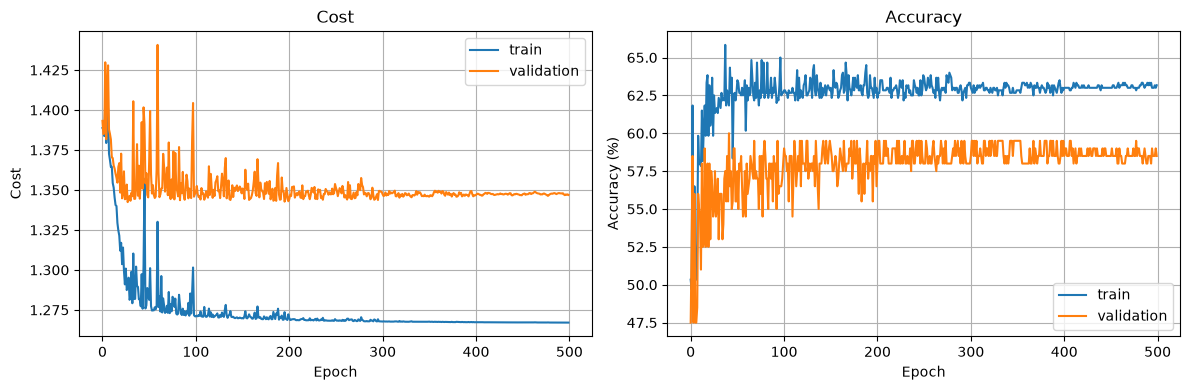

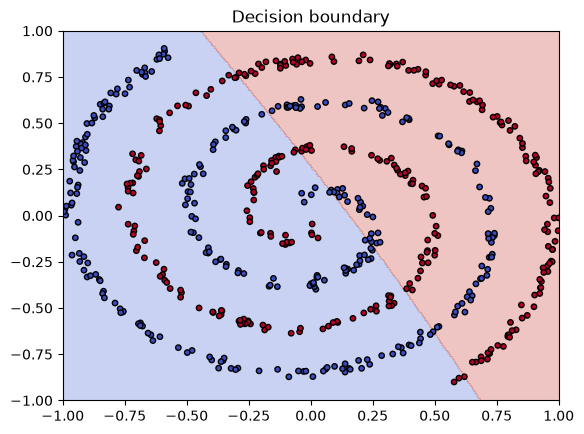

In [198]:
set_seed(42)
X, y = generate_spirals(n_points=500)
idx = np.random.permutation(len(X))
X, y = X[idx], y[idx]
pairs_train = [(X[i].reshape(2, 1), vec(int(y[i, 0]))) for i in range(600)]
pairs_val   = [(X[i].reshape(2, 1), int(y[i, 0])) for i in range(600, 800)]

set_seed(0)
mlp_r = Network([2, 20, 20, 2], activation='relu', init='he')
history_r = mlp_r.SGD(pairs_train, 500, 20, 0.15, 0.1, pairs_val)
plot_history(history_r)
plot_boundary(mlp_r, X[:600], y[:600])

set_seed(0)
mlp_s_normal = Network([2, 20, 20, 2], activation='sigmoid', init='normal')
history_s_normal = mlp_s_normal.SGD(pairs_train, 500, 20, 0.15, 0.1, pairs_val)   
plot_history(history_s_normal)
plot_boundary(mlp_s_normal, X[:600], y[:600])

set_seed(0)
mlp_s_hp = Network([2, 20, 20, 2], activation='sigmoid', init='normal')
history_s_hp = mlp_s_hp.SGD(pairs_train, 1000, 30, 1.75, 0.1, pairs_val)   
plot_history(history_s_hp)
plot_boundary(mlp_s_hp, X[:600], y[:600])

set_seed(0)
mlp_s_xavier = Network([2, 20, 20, 2], activation='sigmoid', init='xavier')
history_s_xavier = mlp_s_xavier.SGD(pairs_train, 500, 20, 0.15, 0.1, pairs_val)   
plot_history(history_s_xavier)
plot_boundary(mlp_s_xavier, X[:600], y[:600])

In [199]:
pairs_test = [(X[i].reshape(2,1), int(y[i,0])) for i in range(800, 1000)]
print("test acc:", 100*mlp_r.evaluate(pairs_test)/len(pairs_test))

test acc: 99.5
